## Computer Vision Project (Phase 3)

## Imports

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split

from torchvision.datasets import ImageFolder
from torchvision import transforms
import torchvision.models as models

import matplotlib.pyplot as plt
import numpy as np

from torchmetrics import Accuracy
from tqdm import tqdm

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report, RocCurveDisplay

## Utils & Functions

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [4]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [5]:
seed = 0

def set_seed(seed):
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
      torch.cuda.manual_seed(seed)

In [6]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, epoch=None):
    model.train()
    loss_train = AverageMeter()
    acc_train = Accuracy(task="multiclass", num_classes=2).to(device)
    with tqdm(train_loader, unit="batch") as tepoch:
        for inputs, targets in tepoch:
            if epoch is not None:
                tepoch.set_description(f"Epoch {epoch}")
            inputs = inputs.to(device)
            targets = targets.to(device)
            
            optimizer.zero_grad()

            outputs = model(inputs)
      
            loss = loss_fn(outputs, targets)

            loss.backward()
            optimizer.step()

            loss_train.update(loss.item())
            acc_train(outputs, targets.int())
            tepoch.set_postfix(loss=loss_train.avg, accuracy=100.*acc_train.compute().item())
    return model, loss_train.avg, acc_train.compute().item()

In [7]:
def validation(model, test_loader, loss_fn):
    model.eval()
    with torch.no_grad():
        loss_valid = AverageMeter()
        acc_valid = Accuracy(task="multiclass", num_classes=2).to(device)
        for i, (inputs, targets) in enumerate(test_loader):
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = loss_fn(outputs, targets)
      
            loss_valid.update(loss.item())
            acc_valid(outputs, targets.int())
    return loss_valid.avg, acc_valid.compute().item()

In [8]:
def normalize_image(image):
  image_min = image.min()
  image_max = image.max()
  image.clamp_(min = image_min, max = image_max)
  image.add_(-image_min).div_(image_max - image_min + 1e-5)
  return image

def plot_images(images, labels, normalize=True):
  n_images = len(images)

  rows = int(np.sqrt(n_images))
  cols = int(np.sqrt(n_images))

  fig = plt.figure(figsize=(10, 10))

  for i in range(rows*cols):

    ax = fig.add_subplot(rows, cols, i+1)
    
    image = images[i]
    if normalize:
      image = normalize_image(image)

    ax.imshow(image.permute(1, 2, 0).cpu().numpy(), cmap='gray')
    ax.set_title(labels[i].item())
    ax.axis('off')

In [9]:
def num_params(model):
    nums = sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6
    return nums

In [10]:
def specificity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    specificity_per_class = {}
    for i in range(2):
        tn = cm[i, i]
        fp = np.sum(cm[:, i]) - tn
        specificity_per_class[i] = tn / (tn + fp)
    return specificity_per_class

In [11]:
def plot_epoch(epoch_counter, loss_train_hist, loss_valid_hist, acc_train_hist, acc_valid_hist):
    plt.figure(figsize=(12,4))

    plt.subplot(1, 2, 1)
    plt.plot(range(epoch_counter), loss_train_hist, 'r-', label='Train')
    plt.plot(range(epoch_counter), loss_valid_hist, 'b-', label='Validation')
    plt.title('Loss of each epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(range(epoch_counter), acc_train_hist, 'r-', label='Train')
    plt.plot(range(epoch_counter), acc_valid_hist, 'b-', label='Validation')
    plt.title('Accuracy of each epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.grid(True)
    plt.legend()

In [12]:
def evaluate(model, loader, title):
    model.eval()

    all_preds = []
    all_labels = []

    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        with torch.no_grad():
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    ConfusionMatrixDisplay.from_predictions(all_preds, all_labels)
    RocCurveDisplay.from_predictions(all_labels, all_preds)
    print(classification_report(all_preds, all_labels))
    print(specificity(all_labels, all_preds))

## Dataset

In [13]:
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.Grayscale()
])
dataset = ImageFolder(root='./datasets/DataSet3/')#, transform=transform)

In [14]:
set_seed(seed)
generator1 = torch.Generator().manual_seed(0)
train_set, valid_set, test_set = random_split(dataset, [0.75, 0.1, 0.15], generator=generator1)

# ViT

In [15]:
set_seed(seed)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(60),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.55, 0.55, 0.55], std=[0.22, 0.22, 0.22])])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.55, 0.55, 0.55], std=[0.22, 0.22, 0.22])])

generator1 = torch.Generator().manual_seed(0)
train_set, valid_set, test_set = random_split(dataset, [0.75, 0.1, 0.15], generator=generator1)

train_set.dataset.transform = train_transform
test_set.dataset.transform = test_transform
valid_set.dataset.transform = test_transform

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=256, shuffle=False)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

In [16]:
x, y = next(iter(train_loader))
print(x.shape)
print(y)

torch.Size([64, 3, 224, 224])
tensor([0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1,
        1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0])


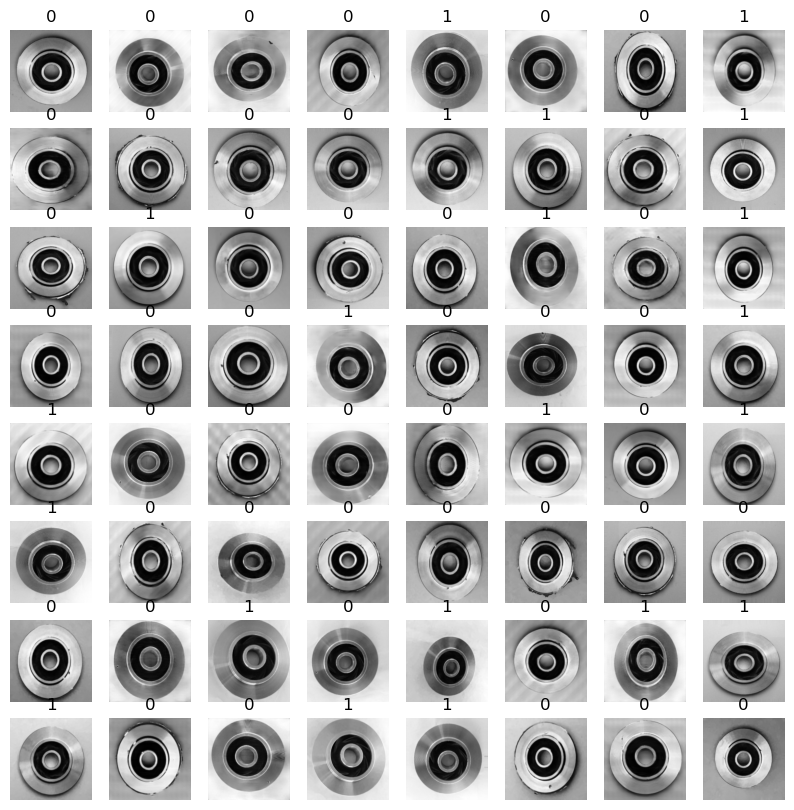

In [17]:
# 0 for defected, 1 for ok
batch = next(iter(train_loader))
plot_images(batch[0], batch[1])

In [18]:
set_seed(seed)
def ViT():
    network = models.vit_b_16(weights='ViT_B_16_Weights.IMAGENET1K_V1')
    network.heads.head = nn.Linear(768, 2)
    network.requires_grad_(False)
    network.heads.requires_grad_(True)
    
    return network

In [26]:
set_seed(seed)
model = ViT().to(device)

In [27]:
set_seed(seed)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

In [28]:
loss_train_hist = []
loss_valid_hist = []

acc_train_hist = []
acc_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [31]:
set_seed(seed)
num_epochs = 5 # ran for 10 epochs before this

for epoch in range(num_epochs):
    model, loss_train, acc_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter)

    loss_valid, acc_valid = validation(model, test_loader, loss_fn)

    loss_train_hist.append(loss_train)
    loss_valid_hist.append(loss_valid)

    acc_train_hist.append(acc_train)
    acc_valid_hist.append(acc_valid)

    if loss_valid < best_loss_valid:
        torch.save(model, './models/Phase 3.pt')
        best_loss_valid = loss_valid

    print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
    print()

    epoch_counter += 1

Epoch 10: 100%|██████████| 15/15 [00:09<00:00,  1.51batch/s, accuracy=95.9, loss=0.116]


Valid: Loss = 0.1655, Acc = 0.9251



Epoch 11: 100%|██████████| 15/15 [00:09<00:00,  1.55batch/s, accuracy=95.9, loss=0.111]


Valid: Loss = 0.1427, Acc = 0.9412



Epoch 12: 100%|██████████| 15/15 [00:09<00:00,  1.51batch/s, accuracy=96.8, loss=0.111]


Valid: Loss = 0.1365, Acc = 0.9465



Epoch 13: 100%|██████████| 15/15 [00:09<00:00,  1.53batch/s, accuracy=97, loss=0.102]   


Valid: Loss = 0.1447, Acc = 0.9412



Epoch 14: 100%|██████████| 15/15 [00:09<00:00,  1.56batch/s, accuracy=96.7, loss=0.0974]


Valid: Loss = 0.1359, Acc = 0.9519



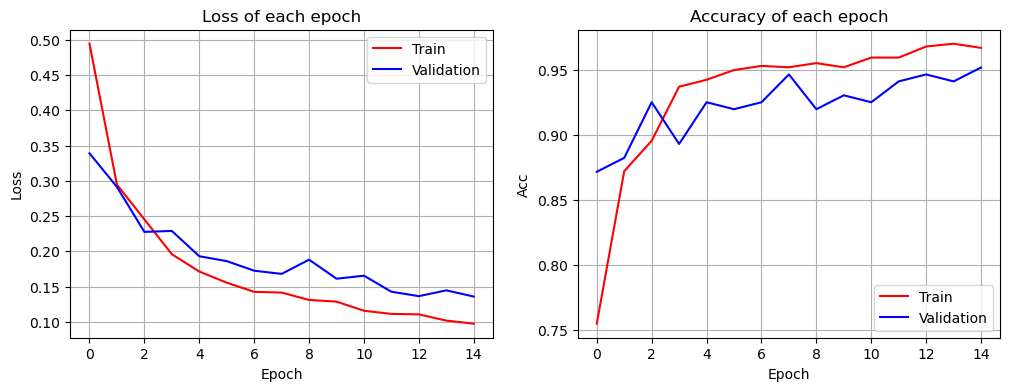

In [32]:
plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(range(epoch_counter), loss_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), loss_valid_hist, 'b-', label='Validation')
plt.title('Loss of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(epoch_counter), acc_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), acc_valid_hist, 'b-', label='Validation')
plt.title('Accuracy of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Acc')
plt.grid(True)
plt.legend()

In [33]:
model = torch.load('./models/Phase 3.pt')

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       554
           1       0.97      0.97      0.97       384

    accuracy                           0.98       938
   macro avg       0.97      0.98      0.97       938
weighted avg       0.98      0.98      0.98       938

{0: 0.9765342960288809, 1: 0.9739583333333334}


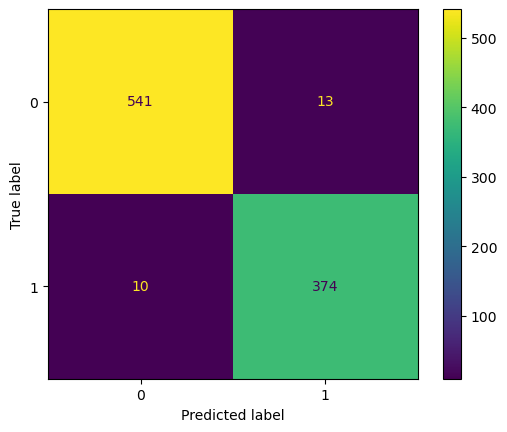

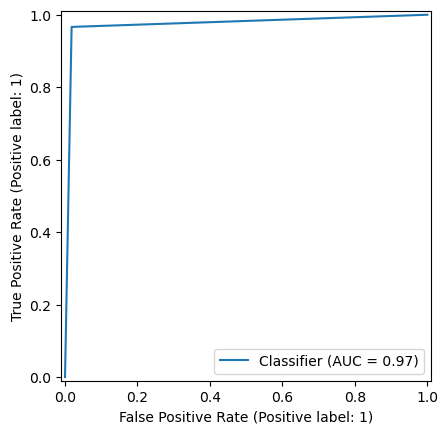

In [34]:
evaluate(model, train_loader, 'Train')

              precision    recall  f1-score   support

           0       0.99      0.95      0.97        84
           1       0.91      0.98      0.94        41

    accuracy                           0.96       125
   macro avg       0.95      0.96      0.96       125
weighted avg       0.96      0.96      0.96       125

{0: 0.9523809523809523, 1: 0.975609756097561}


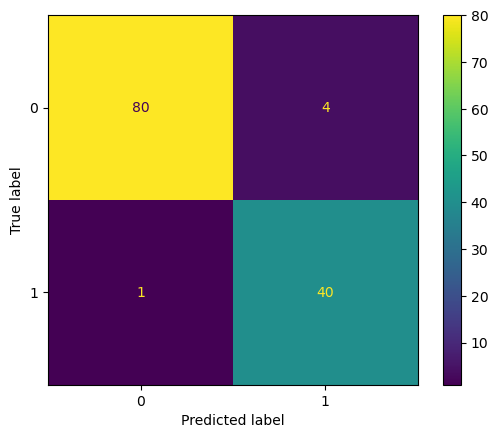

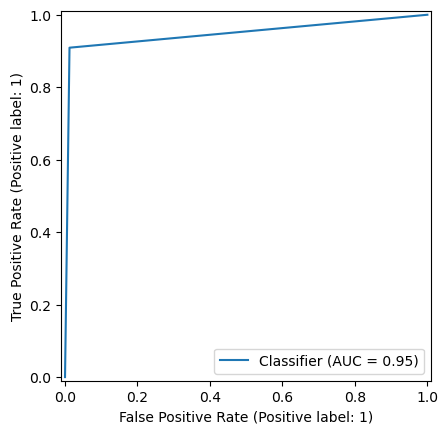

In [35]:
evaluate(model, valid_loader, 'Valid')

              precision    recall  f1-score   support

           0       0.97      0.96      0.96       119
           1       0.93      0.94      0.93        68

    accuracy                           0.95       187
   macro avg       0.95      0.95      0.95       187
weighted avg       0.95      0.95      0.95       187

{0: 0.957983193277311, 1: 0.9411764705882353}


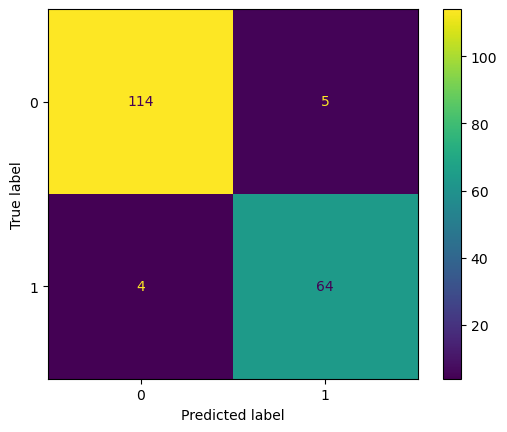

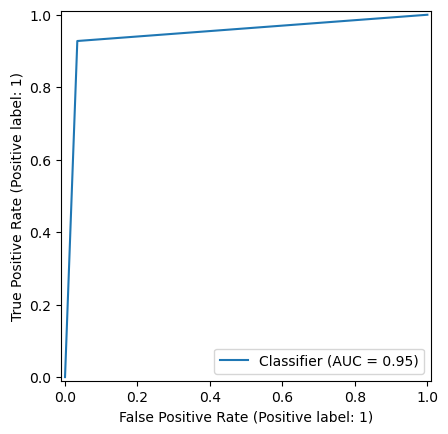

In [36]:
evaluate(model, test_loader, 'Test')